<a href="https://colab.research.google.com/github/Briggernaut/MusicLeagueAnalysis/blob/main/MusicLeagueAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#@title Read in Data
#load dataframes
import pandas as pd
import ipywidgets as widgets
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np

#formatting
BOLD = '\033[1m'
RESET = '\033[0m'

# Convenience functions, move to lib
def get_player_name_from_id(id):
    return competitors_df.loc[competitors_df['ID']==id,'Name'].values[0]

def get_round_name_from_id(id):
    return rounds_df.loc[rounds_df['ID']==id,'Name'].values[0]

# Load a local CSV file
competitors_df = pd.read_csv("data/Season 1/competitors.csv")
rounds_df = pd.read_csv("data/Season 1/rounds.csv")
submissions_df = pd.read_csv("data/Season 1/submissions.csv")
votes_df = pd.read_csv("data/Season 1/votes.csv")

# convenience definitions
playerIds = competitors_df['ID']
roundIds = rounds_df['ID']

# submissions_df does not have a unique key, make one for easier lookups
submissions_df['uid'] = submissions_df['Spotify URI'] + ' ' + submissions_df['Round ID']
votes_df['uid'] = votes_df['Spotify URI'] + ' ' + votes_df['Round ID']

# Add a column in votes_df for submitted_by_id
lookup_series = submissions_df.set_index('uid')['Submitter ID']
votes_df['Submitter ID'] = votes_df['uid'].map(lookup_series)

# Print Datafram column headers
print('Competitors: ',competitors_df.columns.to_numpy().tolist())
print('Rounds: ',rounds_df.columns.to_numpy().tolist())
print('Submissions: ',submissions_df.columns.to_numpy().tolist())
print('Votes: ',votes_df.columns.to_numpy().tolist())

Competitors:  ['ID', 'Name']
Rounds:  ['ID', 'Created', 'Name', 'Description', 'Playlist URL']
Submissions:  ['Spotify URI', 'Title', 'Album', 'Artist(s)', 'Submitter ID', 'Created', 'Comment', 'Round ID', 'Visible To Voters', 'uid']
Votes:  ['Spotify URI', 'Voter ID', 'Created', 'Points Assigned', 'Comment', 'Round ID', 'uid', 'Submitter ID']


In [2]:
#@title Songs Submitted by Each User (interactive)
#list of songs submitted by each user
songs_submitted = {}
for player in playerIds:
    # Returns the title and artist of every submission from player
    song_list = submissions_df.loc[submissions_df['Submitter ID'] == player, ['Title','Artist(s)']]
    # smush the artist and title together
    song_list['formatted'] = song_list['Title'].str.cat(song_list['Artist(s)'], sep=' by ')
    # turn player id to player name
    player_name = get_player_name_from_id(player)
    # drop the ide field
    song_list = song_list.iloc[:, 1:]
    # dict of list of songs index by player name
    songs_submitted[player_name] = song_list['formatted'].tolist()

#sort the dict alphabetically to make it pretty
songs_submitted = dict(sorted(songs_submitted.items()))

# Define the event handler function for drop down
def on_change(change):
    if change['type'] == 'change' and change['name'] == 'value':
        with output:
            output.clear_output() # Clear previous text
            print(f"{BOLD}Player {change['new']} submitted the following songs:{RESET}")
            print(*songs_submitted[change['new']], sep="\n")

# Create the dropdown
dropdown = widgets.Dropdown(
    options=list(songs_submitted),
    description='Select a player:',
    style={'description_width': 'initial'},
    disabled=False,
)
output = widgets.Output()

# Bind the function to the dropdown's value changes
dropdown.observe(on_change)

# Display both the dropdown and the output container
display(dropdown, output)

Dropdown(description='Select a player:', options=('Adam Kestian', 'Brigette', 'De Wolfe', 'Eric Anderson', 'Hm…

Output()

In [3]:
#@title Calculate player stats
player_votes_stats = []
for player in playerIds:
    # Sum all votes given to a player
    totalVotes = votes_df.loc[votes_df['Submitter ID'] == player, 'Points Assigned'].sum()
    # find the number of rounds they participated in
    count = (submissions_df['Submitter ID'] == player).sum()
    #print (player +' got '+ str(totalVotes) +' votes '+' and participated in '+str(count)+'rounds')
    # Append simple dictionaries to a list
    player_votes_stats.append({'Name': get_player_name_from_id(player), 'Votes For': totalVotes, 'Rounds Participated':count})

# Convert the whole list to a DataFrame all at once
player_stat_df = pd.DataFrame(player_votes_stats)
player_stat_df['Votes per Round'] = player_stat_df['Votes For']/player_stat_df['Rounds Participated']


## Votes per Round


In [4]:
#@title Display list of best votes per round
# sort by votes/round
display_df = player_stat_df[['Name', 'Votes per Round']].sort_values(by='Votes per Round', ascending=False)
# display list
display(display_df.style.hide(axis="index"))

Name,Votes per Round
Mariah,29.333333
mandeepkundal,27.750000
chlo,25.125000
Isaiah Freed,24.250000
De Wolfe,23.812500
Matoos,21.769231
William Dullemond,21.562500
the only John,21.416667
Mick,20.937500
shannon_ar,20.384615


Players with perfect attendance:
Pascal
Mick
William Dullemond
Brigette
darkknave
Adam Kestian
JustLisa

Players who forgot to vote after having submitted a song:


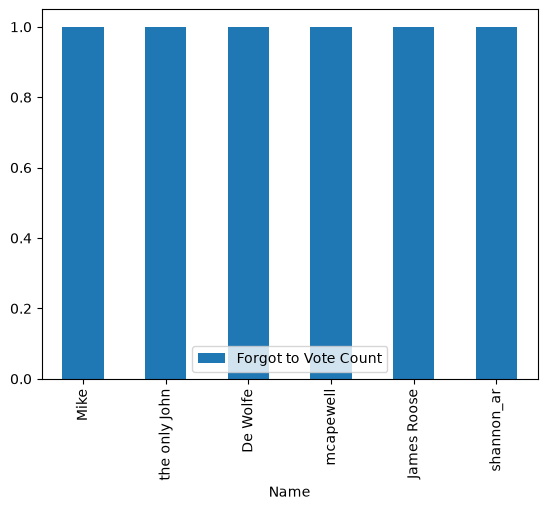

In [5]:
#@title Calculate participation stats
# How many rounds did each player not submit or not vote in?
player_attendance_stats=[]
for player in playerIds:
    rounds_submitted = submissions_df.loc[(submissions_df['Submitter ID'] == player),'Round ID'].tolist()
    rounds_not_submitted  = list(set(roundIds) - set(rounds_submitted))
    # rounds where user submitted but did not vote
    rounds_voted = votes_df.loc[(votes_df['Voter ID'] == player),'Round ID'].tolist()
    # list of rounds, remove those where user voted, remove those where the user did not submit
    rounds_forgot_to_vote = list(set(roundIds) - set(rounds_voted)-set(rounds_not_submitted))
    #convert ids to names
    rounds_submitted = [get_round_name_from_id(round_id) for round_id in rounds_submitted]
    rounds_not_submitted = [get_round_name_from_id(round_id) for round_id in rounds_not_submitted]
    rounds_forgot_to_vote = [get_round_name_from_id(round_id) for round_id in rounds_forgot_to_vote]
    player_attendance_stats.append({'Name': get_player_name_from_id(player), 'Rounds Not Submitted': rounds_not_submitted, 'Forgot to Vote':rounds_forgot_to_vote, 'Perfect Attendance':(len(rounds_not_submitted)==0 and len(rounds_forgot_to_vote)==0) })
player_attendance_df = pd.DataFrame(player_attendance_stats)
#makea column counting how many rounds a player forgot to vote
player_attendance_df['Forgot to Vote Count'] = player_attendance_df['Forgot to Vote'].str.len()
#print(player_attendance_df)
perfect_attendance_list = player_attendance_df.loc[(player_attendance_df['Perfect Attendance'] == True),'Name'].tolist()
print(f"{BOLD}Players with perfect attendance:{RESET}")
print(*perfect_attendance_list, sep="\n")

print(f"\n{BOLD}Players who forgot to vote after having submitted a song:{RESET}")
display_df = player_attendance_df.loc[(player_attendance_df['Forgot to Vote Count'] > 0)].sort_values(by='Forgot to Vote Count', ascending=False)
display_df.plot.bar(x='Name', y='Forgot to Vote Count', rot=90);

Name,Winner,Highest Score,Average Score,Most Votes,Submitted Last,Voted Last
Water,JustLisa,16,10.000000,4,James Roose,mcapewell
Favourite song released before you were born,Pascal,16,10.000000,4,James Roose,Hman
getting ready to win something / pump you up music,the only John,28,15.000000,6,James Roose,jammbler
Nostalgia,De Wolfe,32,20.000000,7,shannon_ar,the only John
Songs with a location in the title of the song or name of the band,mandeepkundal,30,20.000000,8,shannon_ar,the only John
Movie Soundtrack,JustLisa,26,20.000000,6,Hman,James Roose
Epic Openers! (favorite 1st track of any album),Matoos,37,20.000000,7,James Roose,mcapewell
Beatboxing,mandeepkundal,40,20.000000,9,shannon_ar,chlo
Great Song Covers,mandeepkundal,33,19.000000,10,the only John,chlo
Your theme if you were a supervillain,Mick,35,18.947368,5,Puneesh,Eric Anderson


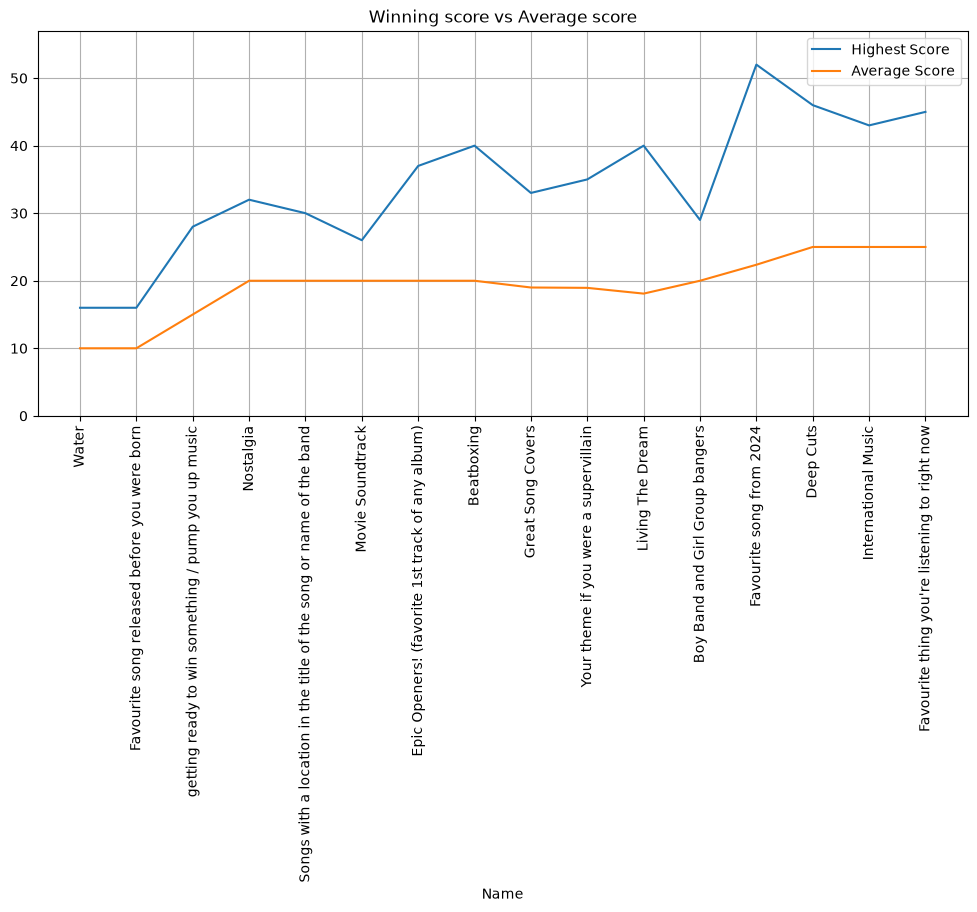

In [6]:
#@title Calculate Round stats
# Round stats who submitted last, who voted last, most votes given by a single person
round_stats = []
for roundId in roundIds:
    voted_last = get_player_name_from_id(votes_df.loc[votes_df[votes_df['Round ID'] == roundId]['Created'].idxmax(), 'Voter ID'])
    submitted_last = get_player_name_from_id(submissions_df.loc[submissions_df[submissions_df['Round ID'] == roundId]['Created'].idxmax(), 'Submitter ID'])
    #print ("voted last "+voted_last)
    #print ("submitted last "+submitted_last)
    most_points = votes_df.loc[votes_df[votes_df['Round ID'] == roundId]['Points Assigned'].idxmax(), 'Points Assigned']
    #print ("most points "+str(most_points))
    #gives us a df with URI and sum of votes
    round_results = votes_df.loc[votes_df['Round ID'] == roundId].groupby('Spotify URI', as_index=False)['Points Assigned'].sum()
    #print(round_results)
    ave_points_per_song= round_results['Points Assigned'].mean()
    #print ("average points per song "+str(ave_points_per_song))
    highest_score = round_results['Points Assigned'].max()
    #print('highest score '+str(highest_score))
    #get winner name from highest score
    winning_song = round_results.loc[round_results['Points Assigned']==highest_score,'Spotify URI'].values[0]
    #print('Winning song ' +winning_song)
    winner =  get_player_name_from_id(submissions_df.loc[(submissions_df['Round ID'] == roundId) & (submissions_df['Spotify URI'] == winning_song),'Submitter ID'].values[0])
    #TODO: need to score tiebreak by # voters, create a whole rank column for use later
    #print('Winner '+winner)
    round_stats.append({'Name': get_round_name_from_id(roundId), 'Winner': winner, 'Highest Score':highest_score, 'Average Score':ave_points_per_song, 'Most Votes':most_points,'Submitted Last': submitted_last, 'Voted Last':voted_last})

round_stats_df = pd.DataFrame(round_stats)
display(round_stats_df.style.hide(axis="index"))
score_v_average = round_stats_df[['Name', 'Highest Score','Average Score']]
ax= score_v_average.set_index('Name').plot.line(title='Winning score vs Average score', grid=True,figsize=(12, 5),ylim=(0, score_v_average['Highest Score'].max() + 5))
ax.set_xticks(np.arange(len(score_v_average)))
ax.set_xticklabels(score_v_average.Name, rotation=90)
plt.show()


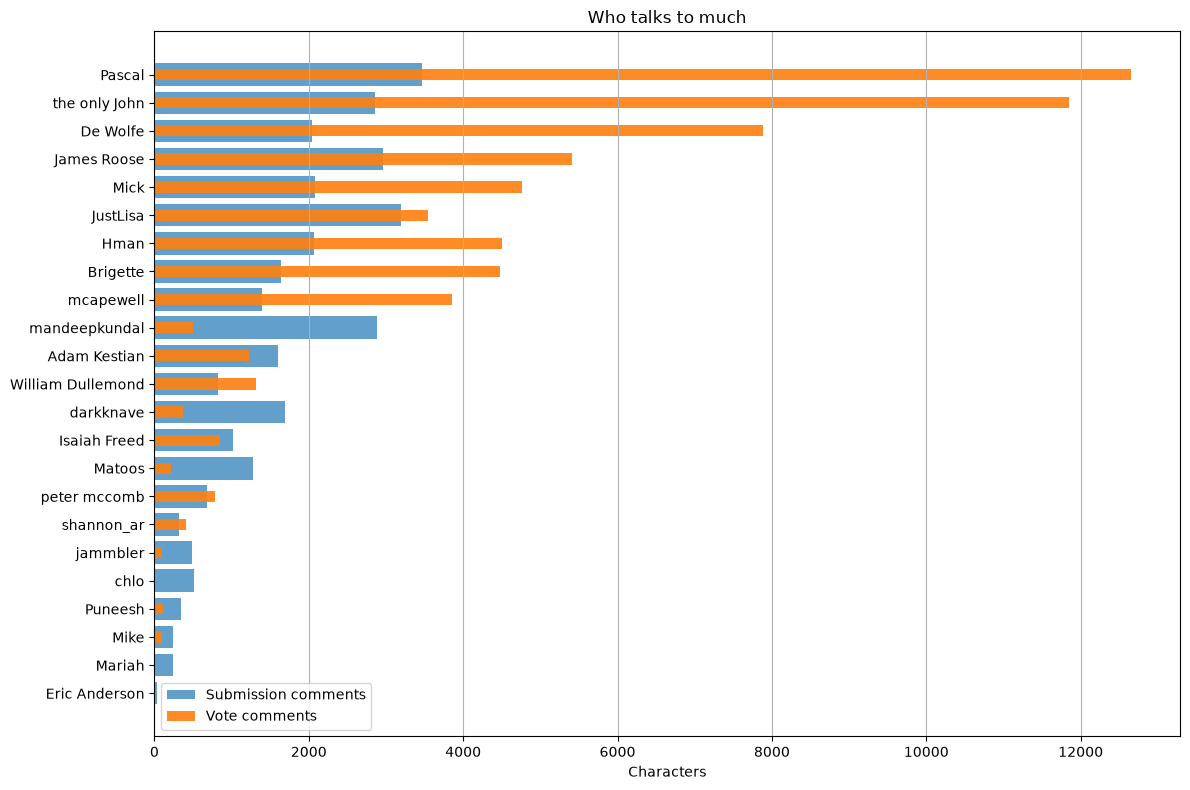

In [9]:
#@title Who Talks the Most
# Total characters each player wrote in submission comments and in voting comments overlaying each other
 
submission_chars = (submissions_df.assign(Chars=submissions_df['Comment'].fillna('').astype(str).str.len())
                    .groupby('Submitter ID')['Chars'].sum())
vote_chars = (votes_df.assign(Chars=votes_df['Comment'].fillna('').astype(str).str.len())
              .groupby('Voter ID')['Chars'].sum())
 
# Combine into one table - should add no char players
chars_df = pd.DataFrame({'Submissions': submission_chars, 'Votes': vote_chars}).fillna(0)
chars_df.index = [get_player_name_from_id(p) for p in chars_df.index]
chars_df = chars_df.loc[(chars_df['Submissions'] + chars_df['Votes']).sort_values().index]  # sort by verbosity
 
y = np.arange(len(chars_df))
fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(y, chars_df['Submissions'], height=0.8, label='Submission comments', alpha=0.7)
ax.barh(y, chars_df['Votes'], height=0.4, label='Vote comments', color='tab:orange', alpha=0.9)
ax.set_yticks(y)
ax.set_yticklabels(chars_df.index)
ax.set_xlabel('Characters')
ax.set_title('Who talks to much')
ax.grid(True, axis='x')
ax.legend()
plt.tight_layout()
plt.show()

In [8]:
# player stats (best round [placement or votes], worst round, who gave you most/least votes, rounds missed
# graph of votes received over round (with a running average line)
# rounds won
# number of comments left
# most emojis? count
# what place did they get in their own round?